# Étude de convergence des PINNs — ablation factorielle (16 configurations)

Objectif : mesurer l'effet de quatre mécanismes sur l'entraînement du SloshingPINN :
1. **Fourier Features**
2. **Segmentation temporelle**
3. **Adaptive sampling** (historique des points sélectionnés)
4. **Adaptive weighting — GradNorm** (historique des poids)

On compare les \(2^4=16\) combinaisons, avec budget d'entraînement, seed et configuration de base identiques. L'analyse porte sur les courbes de pertes, la convergence (seuil, pente, plateau), les points adaptatifs et les poids GradNorm.

> Le notebook s'appuie sur `config.py`, `train.py`, `model.py`, `sampling.py`, `adaptive_weights.py`, `losses.py` et le module `visualization.py` du projet. Exécuter depuis la racine du projet. Les quatre options sont supposées être les attributs `use_fourier_features`, `use_temporal_segmentation`, `use_adaptive_sampling`, `use_adaptive_loss_weights` dans `Config`.

## 1. Imports et environnement

In [1]:
import sys
from pathlib import Path
from itertools import product
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))
print('Répertoire du projet :', ROOT)

from config import Config
from train import train, set_seed
import visualization as viz

RUNS_DIR = ROOT / "models"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Répertoire du projet : /home/ludodo/SINN
Device: cuda


## Construire les 16 configurations

L'ordre des bits est : Fourier, segmentation temporelle, sampling adaptatif, poids adaptatifs. Le code échoue explicitement si les noms de paramètres diffèrent dans votre `Config`, plutôt que de modifier silencieusement l'expérience.

In [2]:
FEATURES = [
    ("fourier", "use_fourier_features"),
    ("sampling", "use_adaptive_sampling"),
    ("temporal", "use_temporal_segmentation"),
    ("gradnorm", "use_adaptive_loss_weights"),
]


experiments = []
for bits in product([0, 1], repeat=4):
    exp_id = "model_ff" + str(bits[0]) + "_as" + str(bits[1]) + "_ts" + str(bits[2]) + "_alw" + str(bits[3])
    experiments.append({
        "id": exp_id,
        "bits": bits,
        **{name: bool(bit) for bit, (name, _) in zip(bits, FEATURES)}
    })

design = pd.DataFrame(experiments)
display(design)
print(f"Nombre de configurations : {len(design)}")

,id,bits,fourier,sampling,temporal,gradnorm
0,model_ff0_as0_ts0_alw0,"(0, 0, 0, 0)",False,False,False,False
1,model_ff0_as0_ts0_alw1,"(0, 0, 0, 1)",False,False,False,True
2,model_ff0_as0_ts1_alw0,"(0, 0, 1, 0)",False,False,True,False
3,model_ff0_as0_ts1_alw1,"(0, 0, 1, 1)",False,False,True,True
4,model_ff0_as1_ts0_alw0,"(0, 1, 0, 0)",False,True,False,False
5,model_ff0_as1_ts0_alw1,"(0, 1, 0, 1)",False,True,False,True
6,model_ff0_as1_ts1_alw0,"(0, 1, 1, 0)",False,True,True,False
7,model_ff0_as1_ts1_alw1,"(0, 1, 1, 1)",False,True,True,True
8,model_ff1_as0_ts0_alw0,"(1, 0, 0, 0)",True,False,False,False
9,model_ff1_as0_ts0_alw1,"(1, 0, 0, 1)",True,False,False,True


Nombre de configurations : 16


Chaque run dispose d'un dossier dédié et conserve les artefacts produits par `train.py` : `history.json`, `history.csv`, checkpoint final, `adaptive_history.npz` pour les points si le sampling adaptatif est actif, et `adaptive_weights.json` pour GradNorm.

## Charger les historiques et contrôler leur intégrité

In [4]:
def load_history(exp_id):
    p = RUNS_DIR / exp_id / "history.json"
    if not p.exists():
        return None
    with p.open(encoding="utf-8") as f:
        return pd.DataFrame(json.load(f))

histories = {e["id"]: load_history(e["id"]) for e in experiments}
available = {k: v for k, v in histories.items() if v is not None and len(v)}
print(f"Historiques disponibles : {len(available)}/{len(experiments)}")
if available:
    print("Clés métriques:", list(next(iter(available.values())).columns))

Historiques disponibles : 16/16
Clés métriques: ['epoch', 'window', 't_left', 't_right', 'total', 'continuity', 'vof', 'momentum_x', 'momentum_y', 'initial_u', 'initial_v', 'initial_alpha', 'wall_u', 'wall_v', 'pressure_gauge']


## Courbes de convergence — perte totale

Comparaison log-échelle. Une courbe par combinaison ; pour ne pas surcharger, on peut ensuite filtrer les configurations.

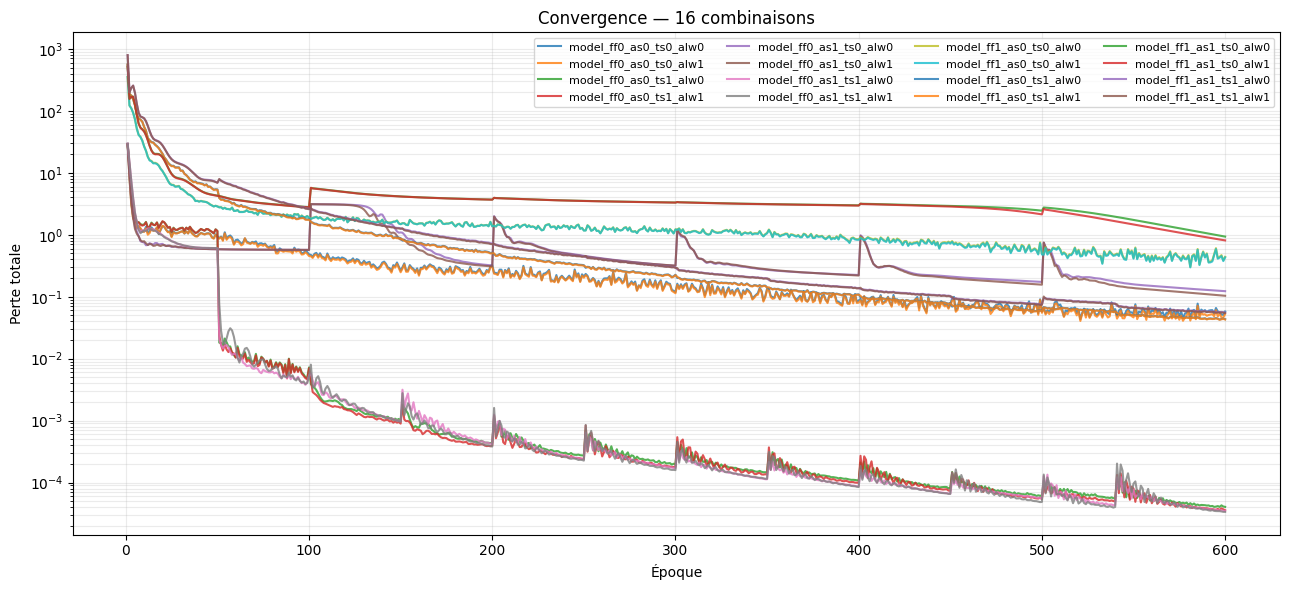

In [5]:
fig, ax = plt.subplots(figsize=(13, 6))
for exp_id, hist in available.items():
    ax.semilogy(hist["epoch"], np.maximum(hist["total"], 1e-16), label=exp_id, alpha=.8)
ax.set(xlabel="Époque", ylabel="Perte totale", title="Convergence — 16 combinaisons")
ax.grid(True, which="both", alpha=.25)
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()

## Pertes physiques séparées

Le train fournit notamment continuity, VOF, momentum x/y, conditions initiales, parois et pressure gauge. Les courbes séparées aident à détecter une perte qui stagne ou domine la somme.

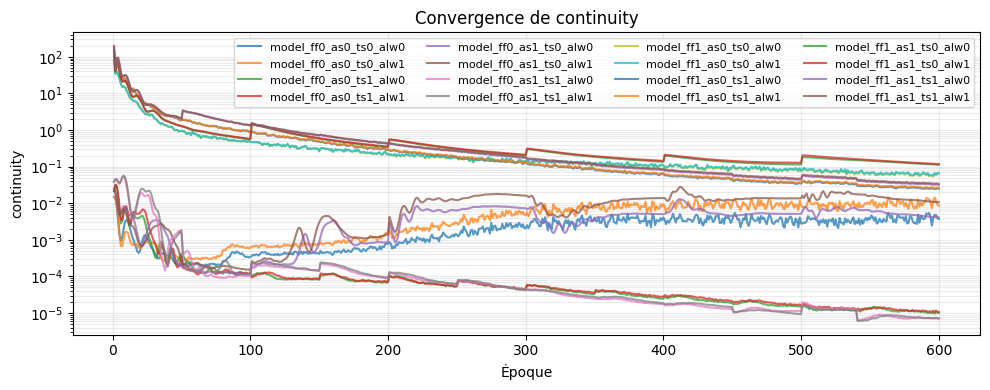

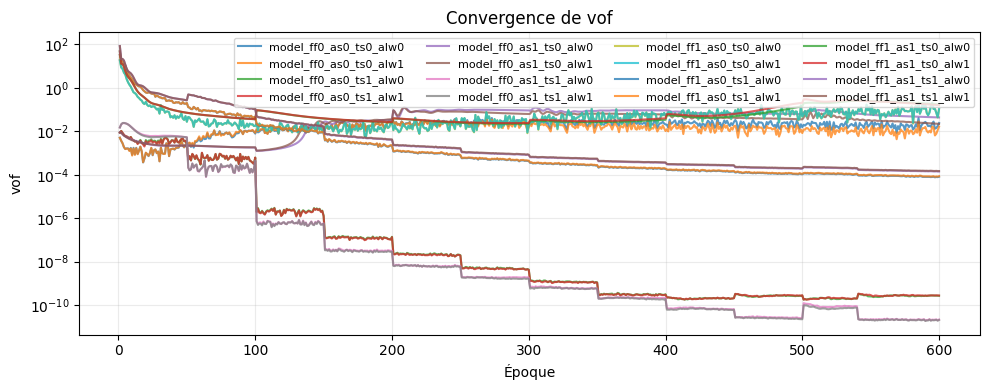

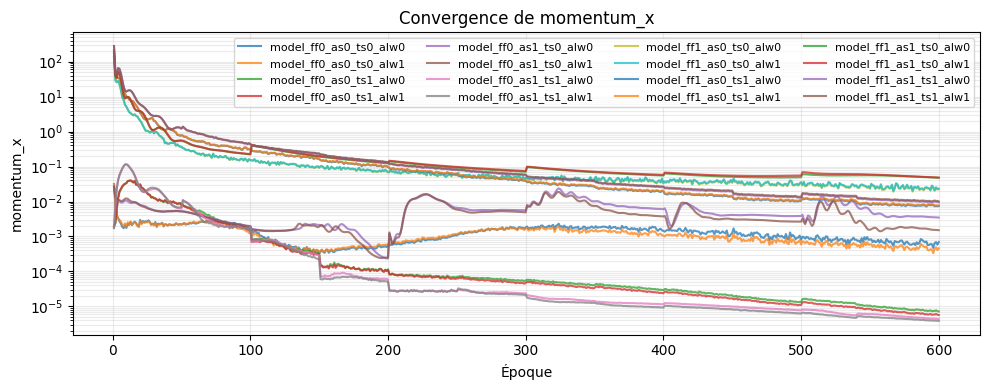

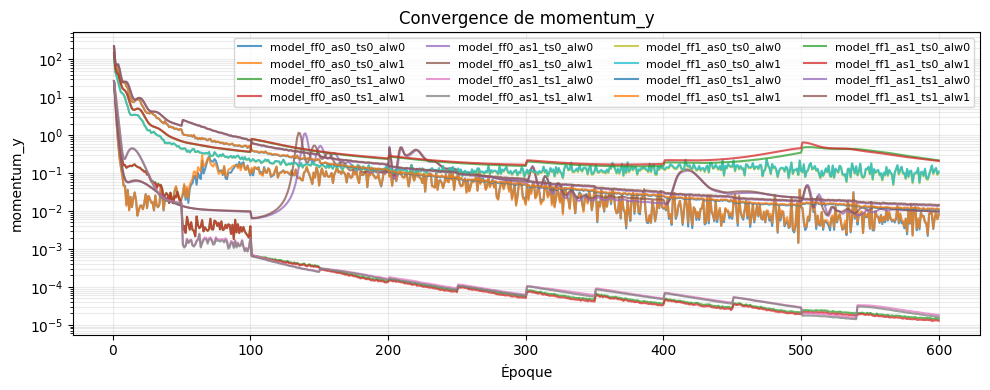

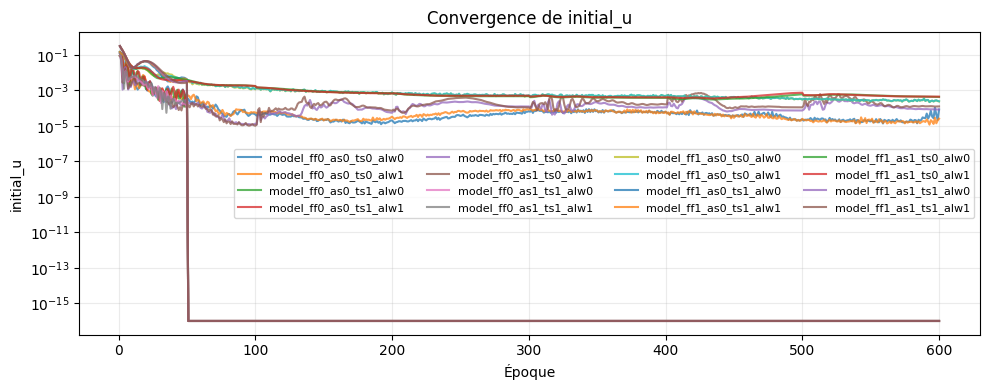

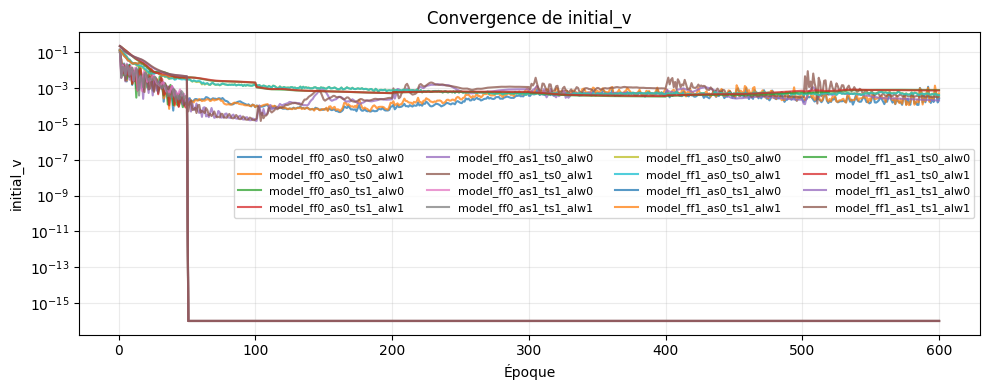

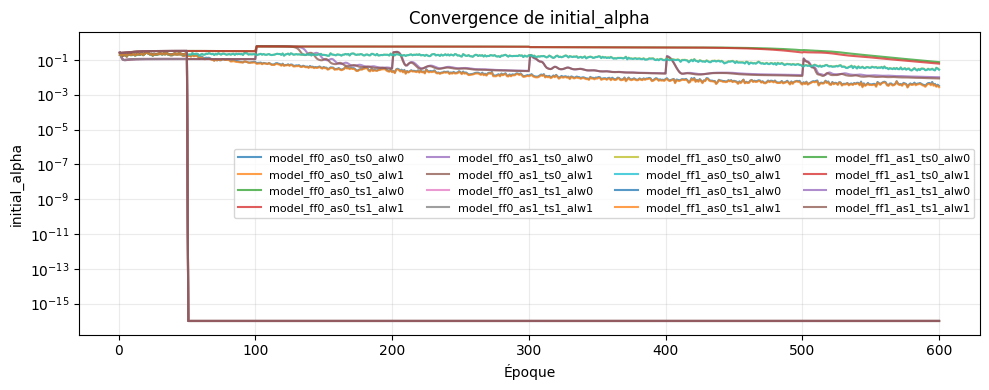

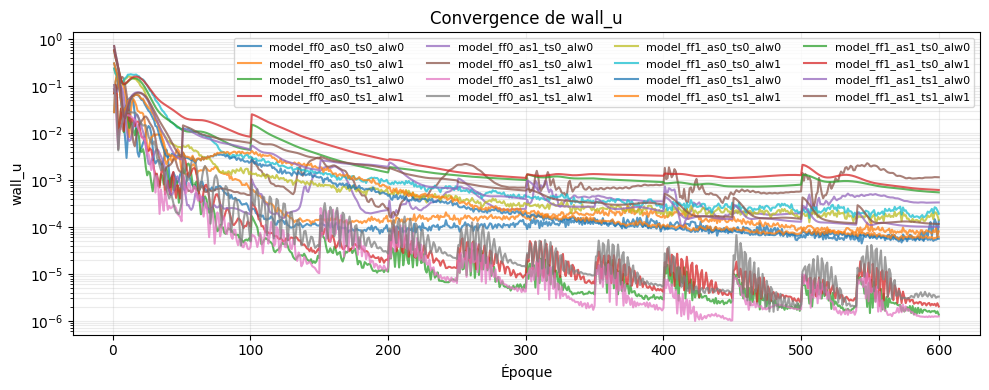

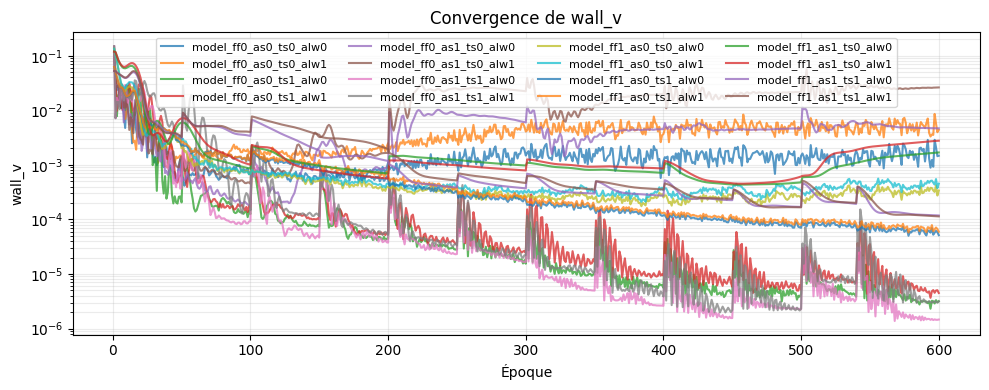

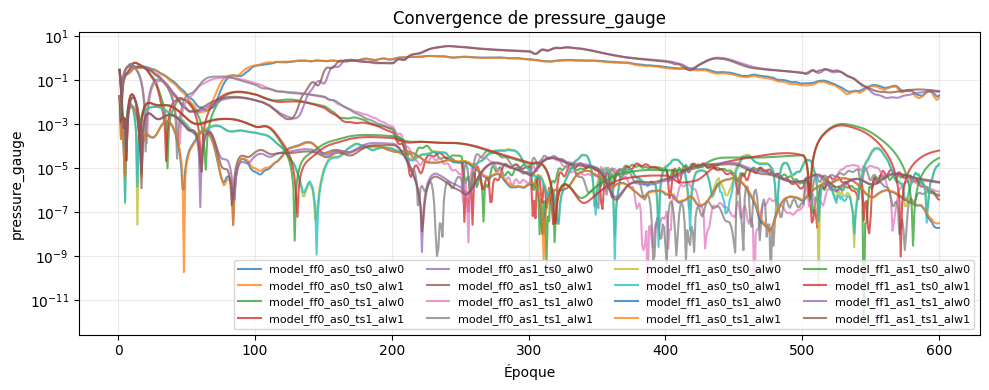

In [6]:
LOSS_KEYS = ["continuity", "vof", "momentum_x", "momentum_y",
             "initial_u", "initial_v", "initial_alpha",
             "wall_u", "wall_v", "pressure_gauge"]
for key in LOSS_KEYS:
    if not any(key in h.columns for h in available.values()):
        continue
    fig, ax = plt.subplots(figsize=(10, 4))
    for exp_id, hist in available.items():
        if key in hist:
            ax.semilogy(hist["epoch"], np.maximum(hist[key], 1e-16), label=exp_id, alpha=.75)
    ax.set(xlabel="Époque", ylabel=key, title=f"Convergence de {key}")
    ax.grid(True, which="both", alpha=.25)
    ax.legend(ncol=4, fontsize=8)
    plt.tight_layout()
    plt.show()

## cartes des résidus

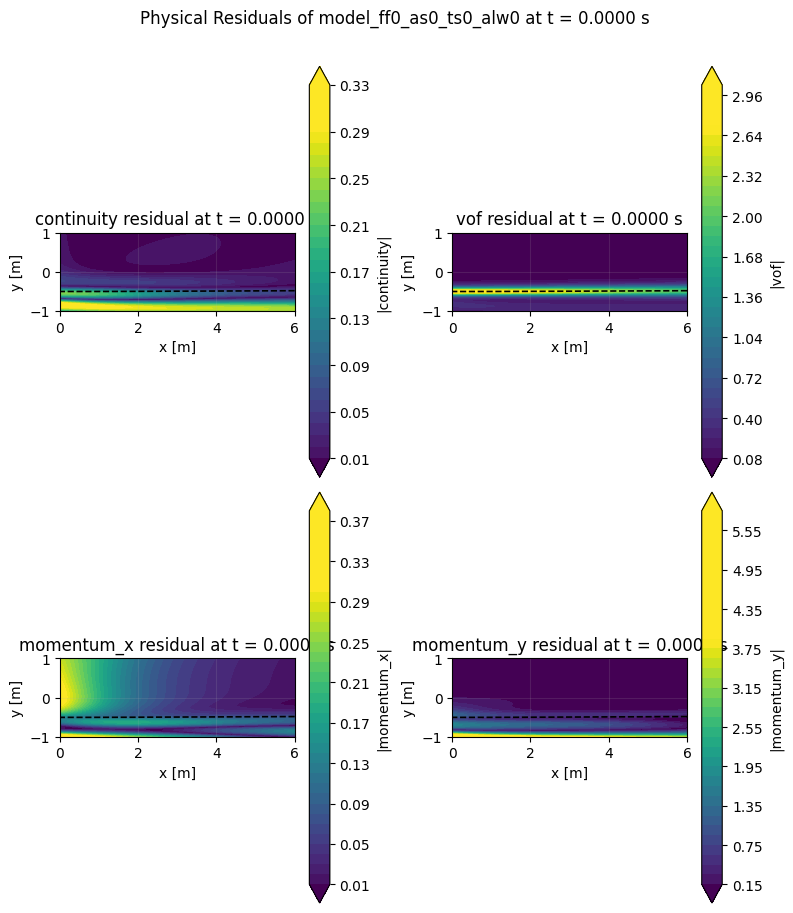

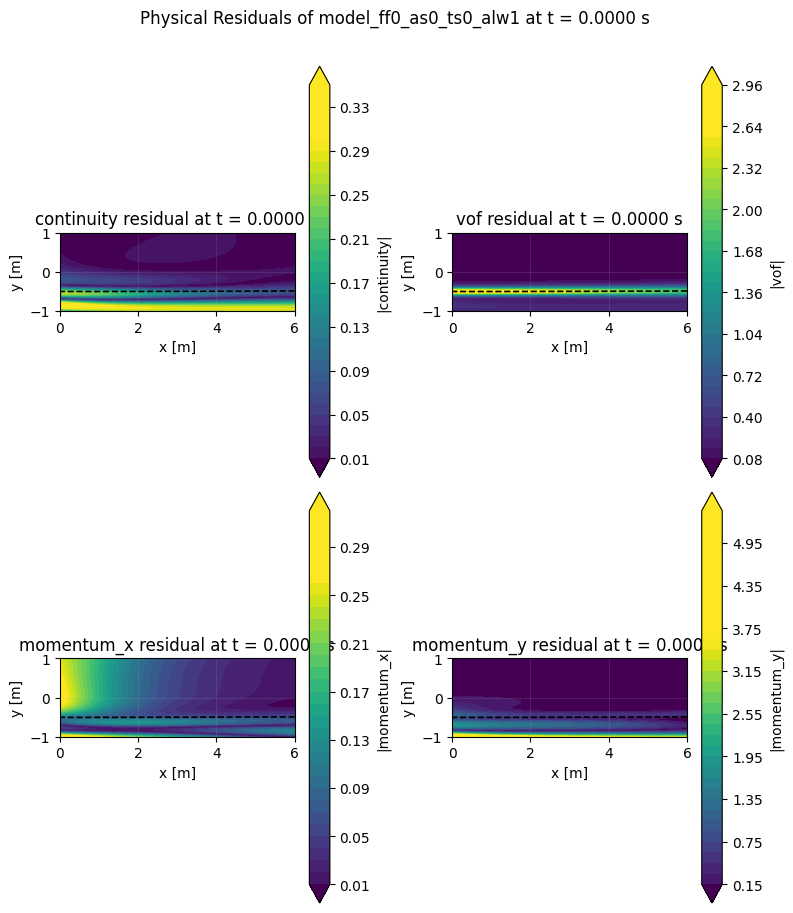

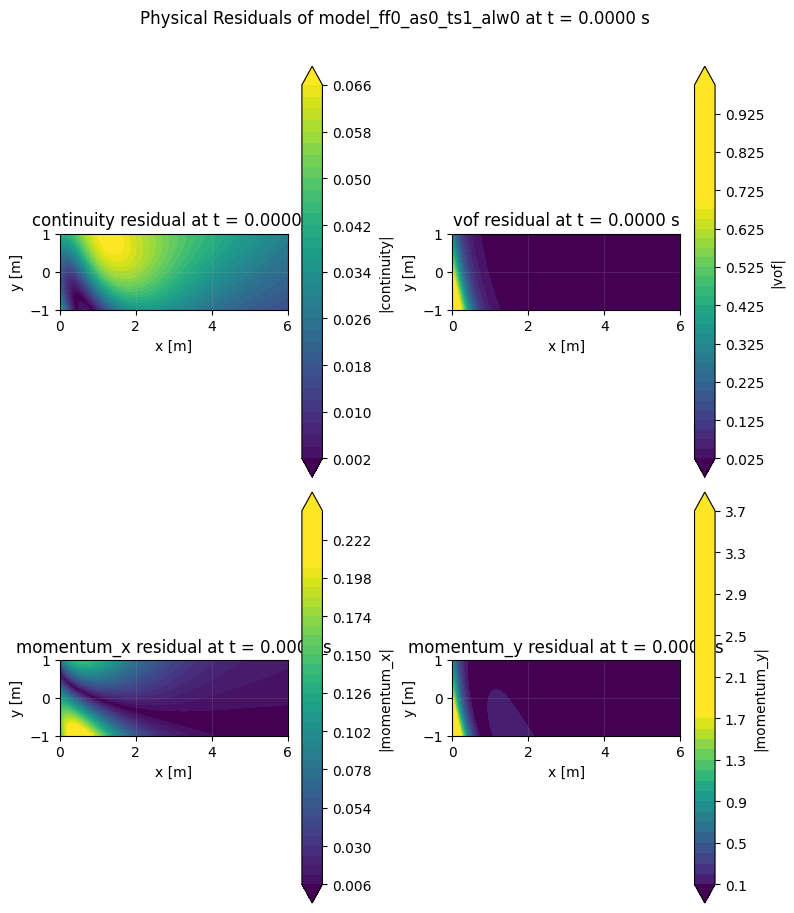

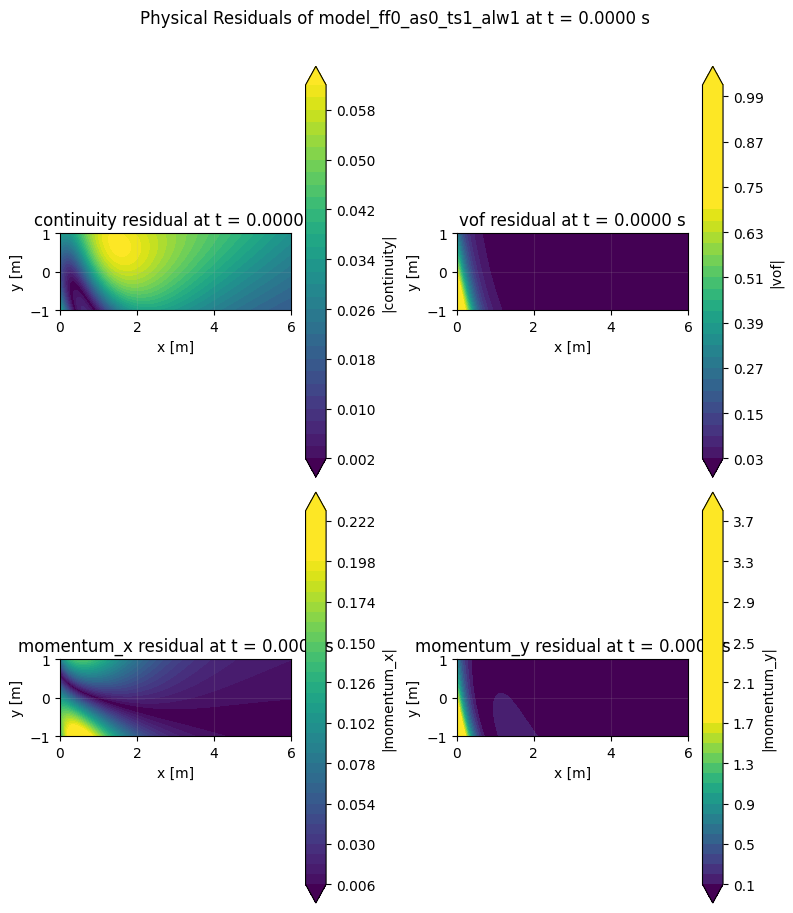

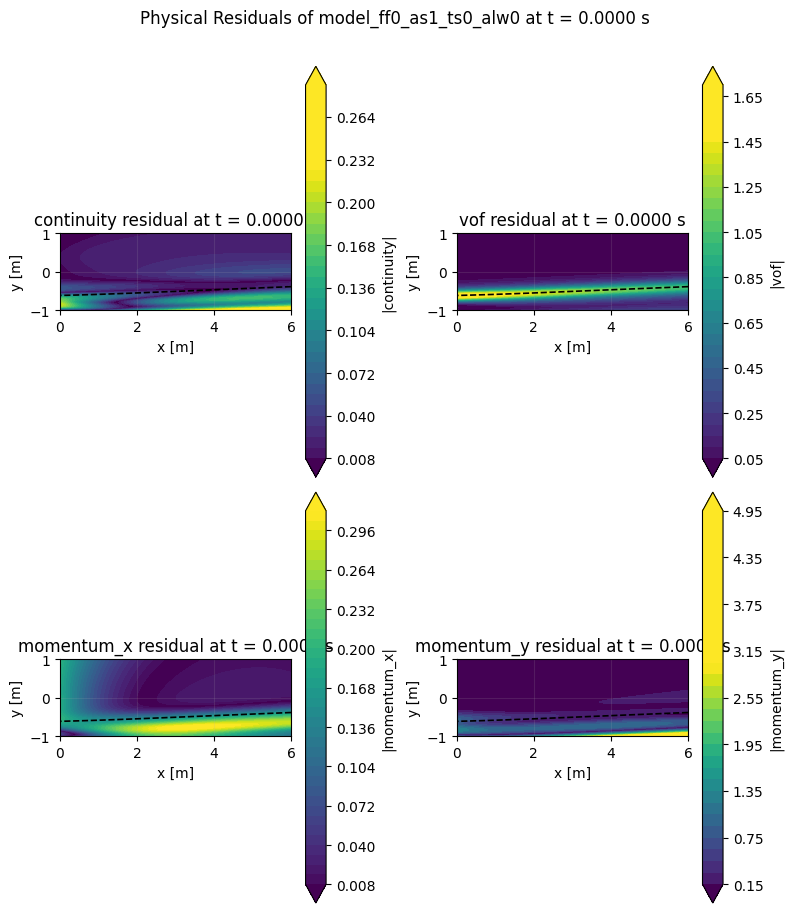

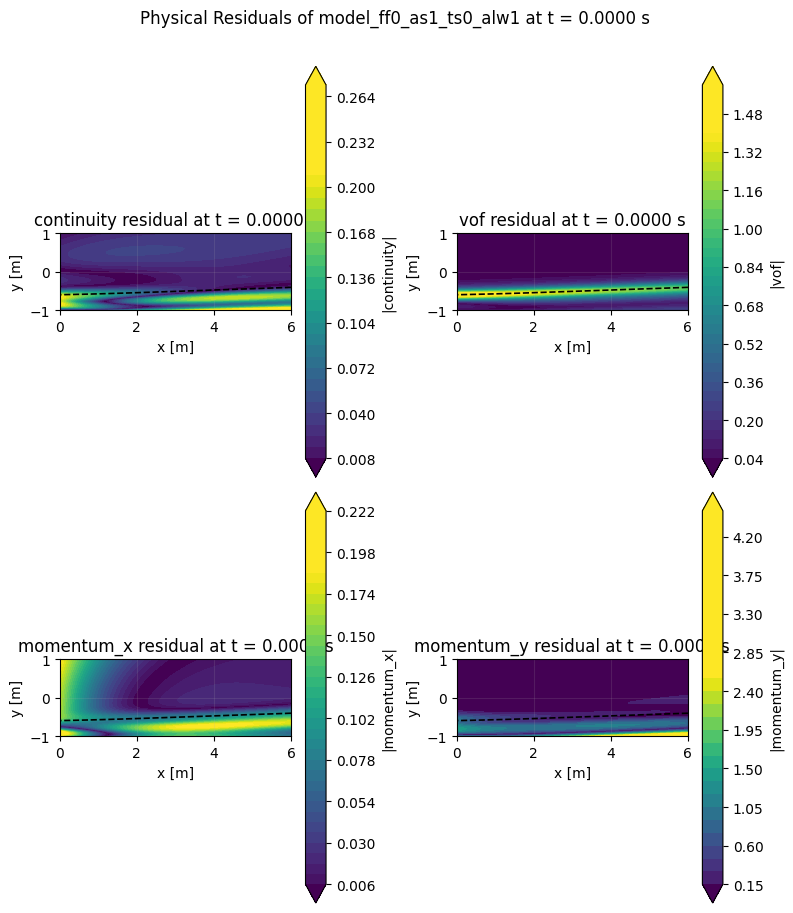

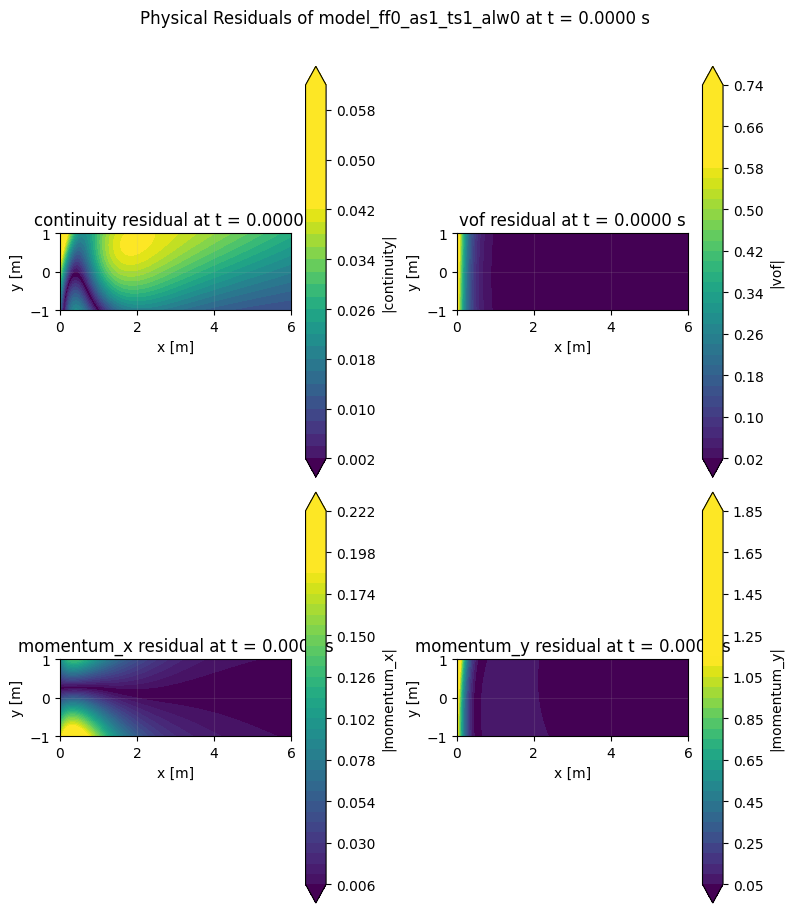

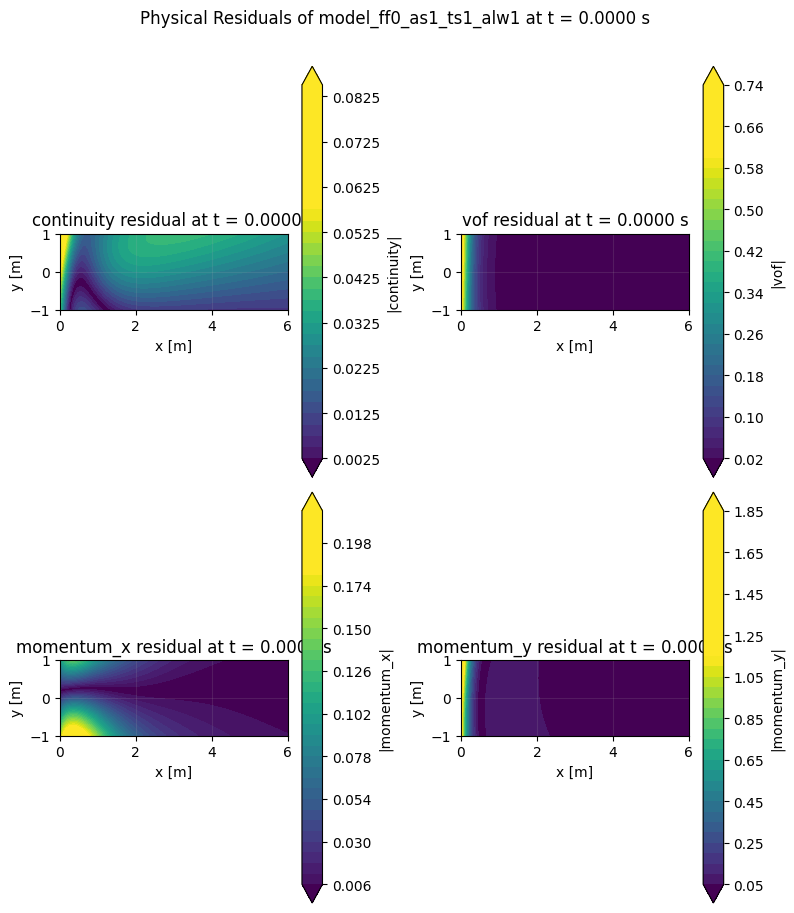

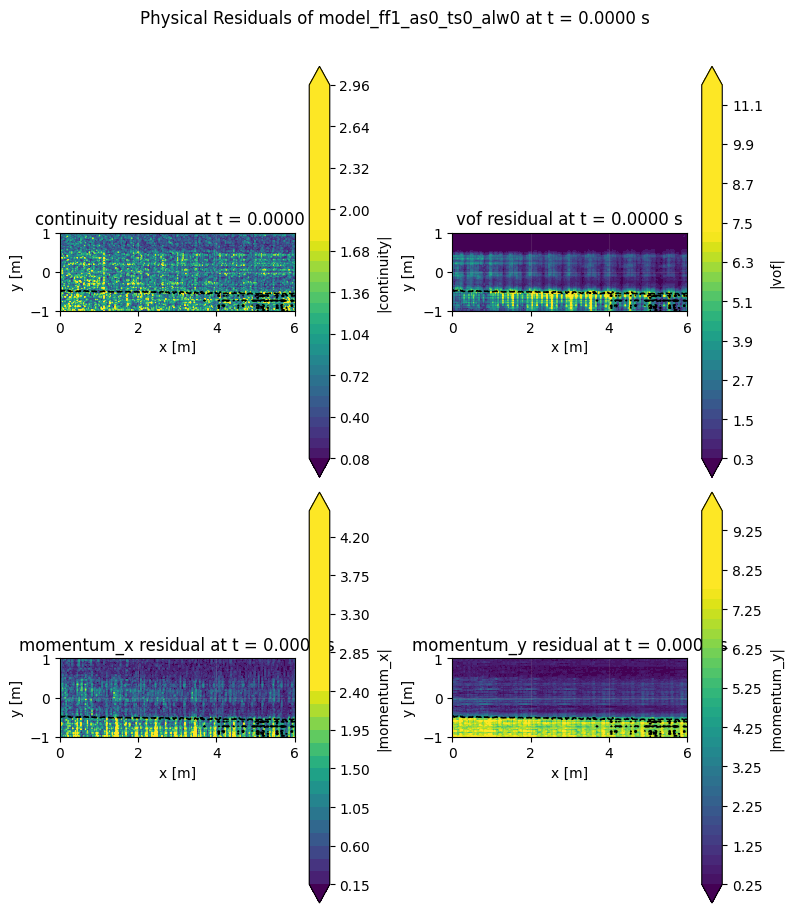

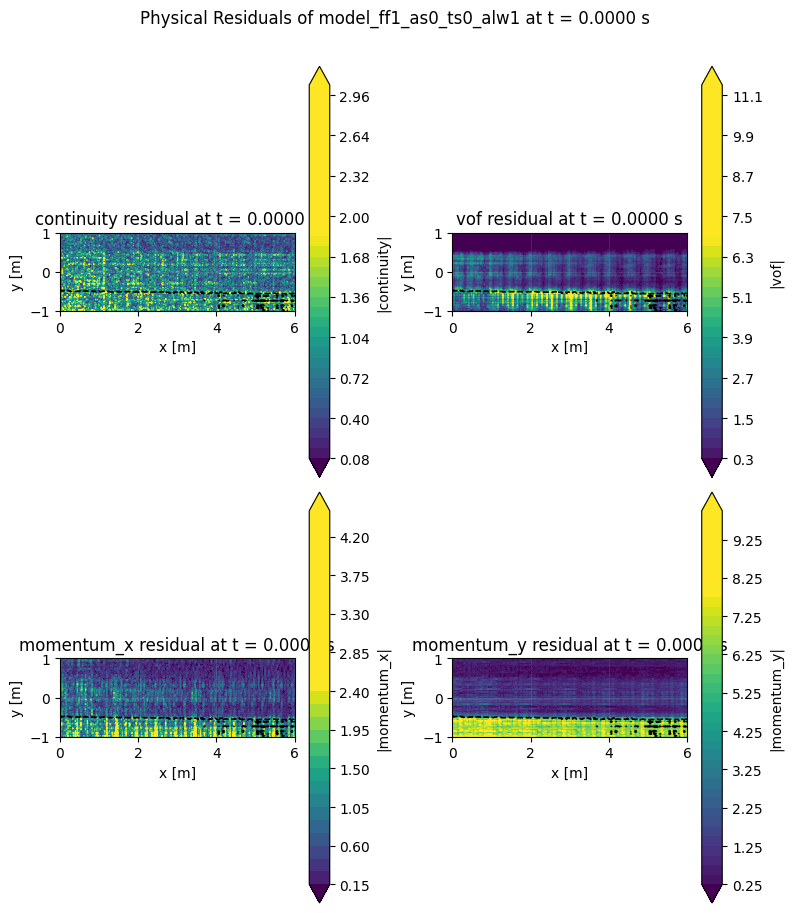

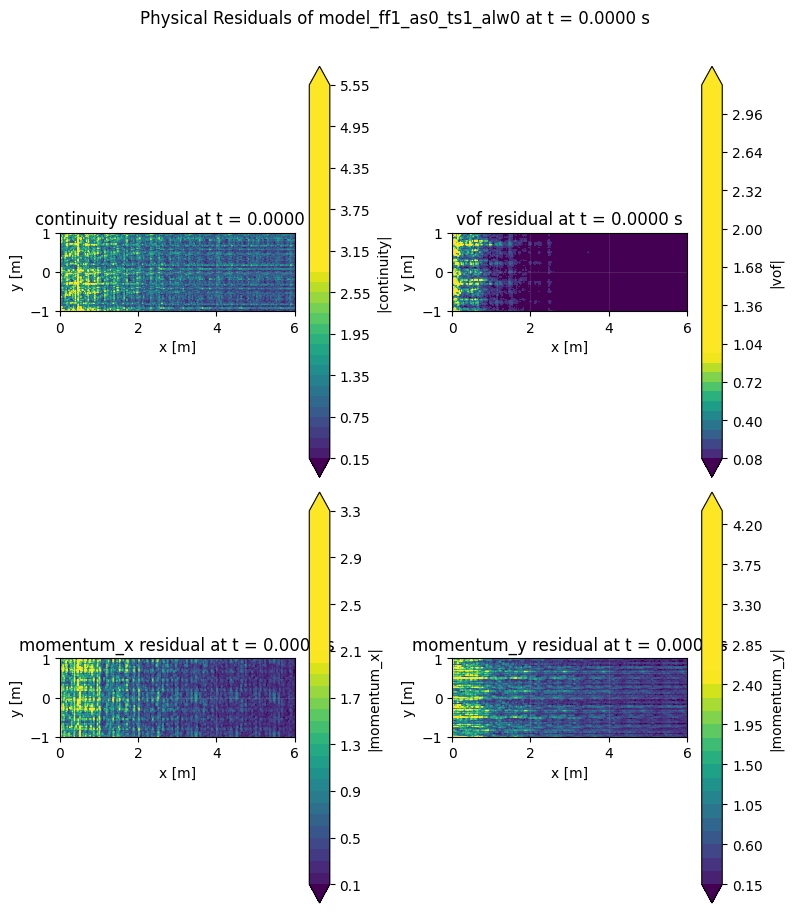

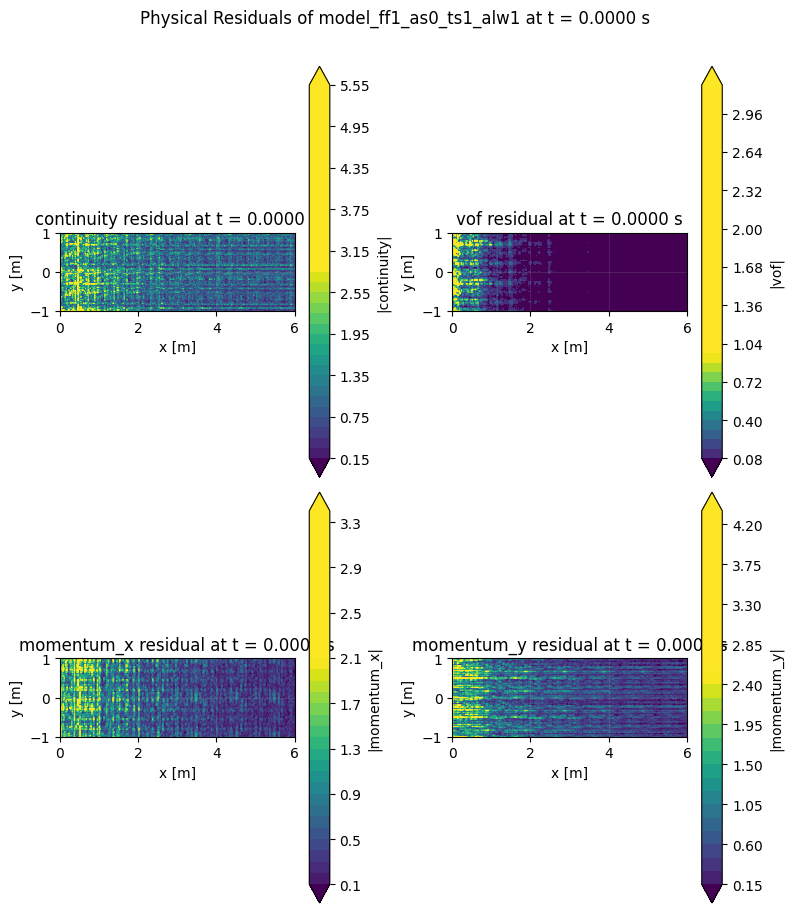

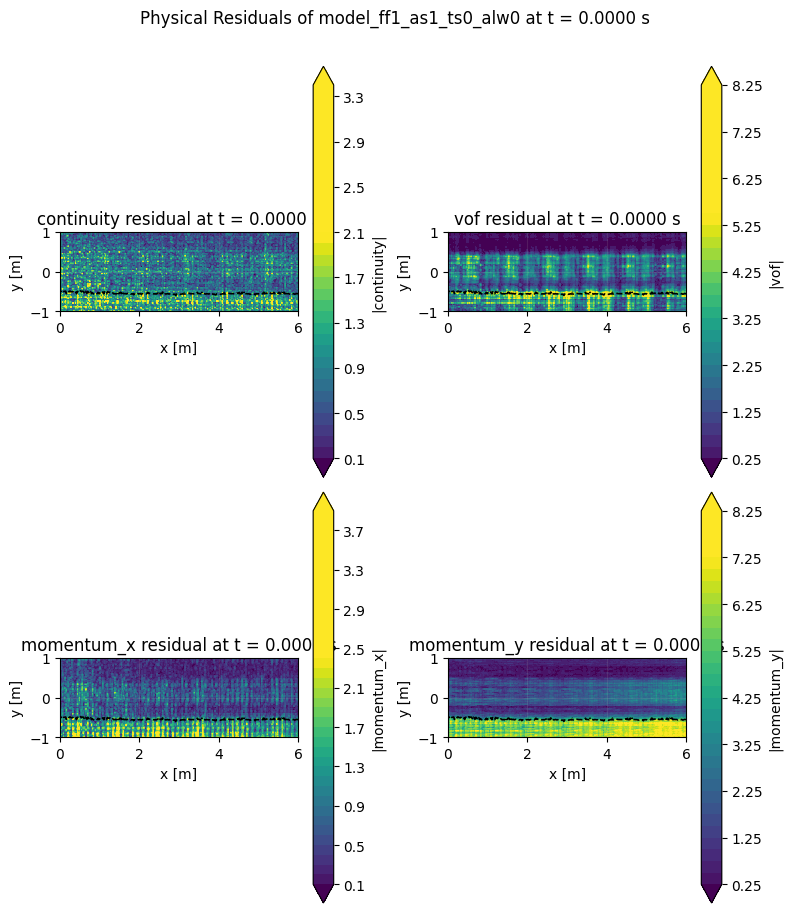

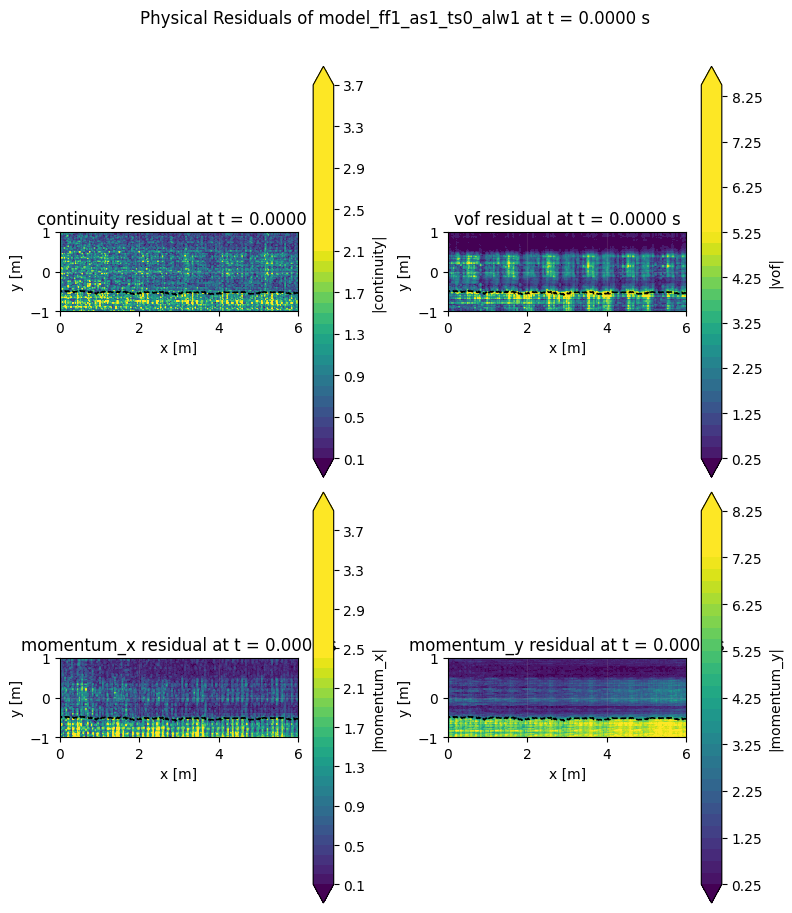

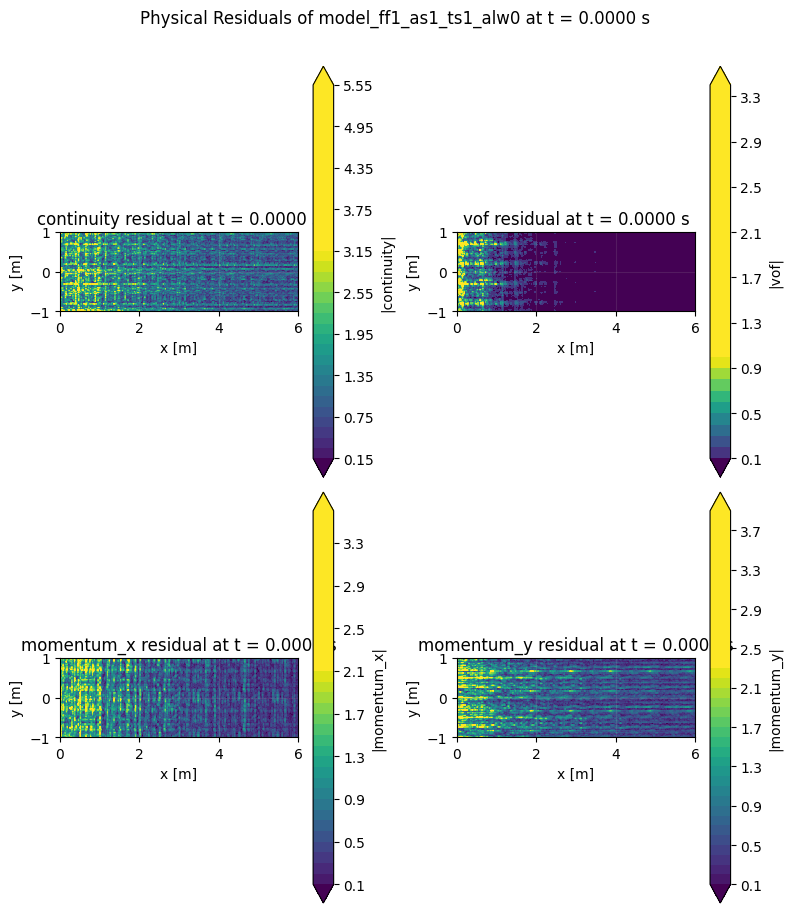

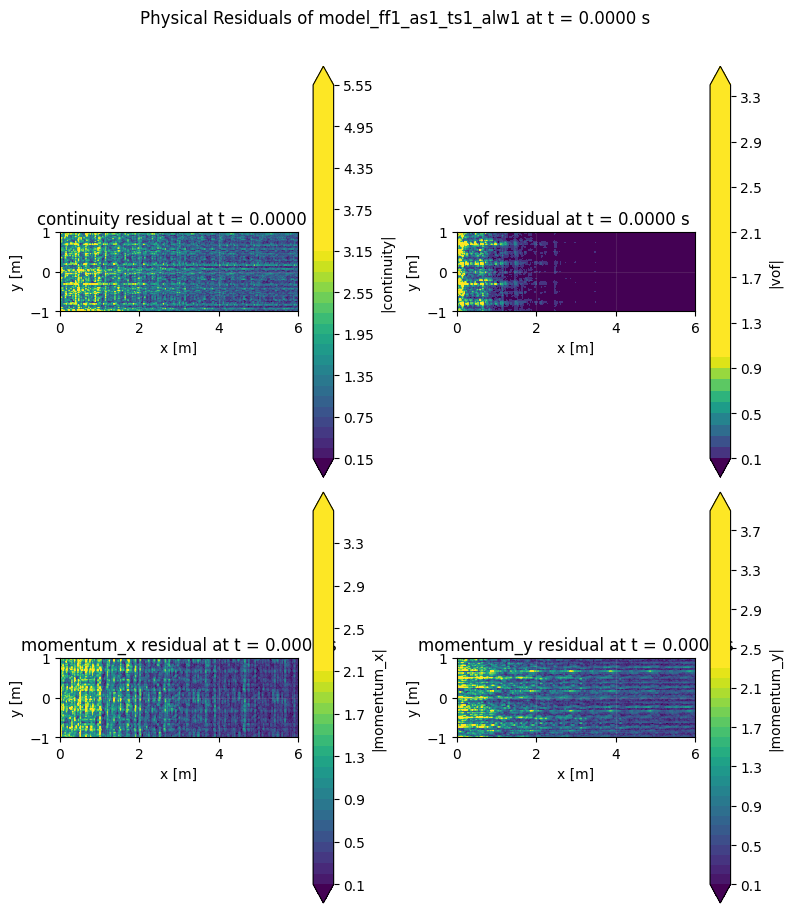

In [7]:
from visualization import plot_residuals, load_model

for exp_id in available.keys():
    plot_residuals(
        load_model(
            ROOT / "models" / exp_id / "checkpoint_final.pt",
            ROOT / "models" / exp_id / "config.json"
        ),
        model_name=exp_id
    )


## Indicateurs de convergence

Les indicateurs suivants sont descriptifs : perte finale, minimum atteint, époque du minimum, pente de log10(perte) sur la dernière partie de la trajectoire, et première époque sous un seuil relatif à la perte initiale. Le seuil relatif ne constitue pas une tolérance physique universelle.

In [11]:
def convergence_metrics(hist, tail_fraction=.2, relative_threshold=1e-3):
    y = np.asarray(hist["total"], dtype=float)
    ep = np.asarray(hist["epoch"], dtype=float)
    valid = np.isfinite(y) & (y > 0)
    y, ep = y[valid], ep[valid]
    if len(y) < 2:
        return {}
    n_tail = max(2, int(np.ceil(tail_fraction * len(y))))
    slope = np.polyfit(ep[-n_tail:], np.log10(y[-n_tail:]), 1)[0]
    threshold = y[0] * relative_threshold
    hits = np.flatnonzero(y <= threshold)
    return {
        "initial": y[0], "final": y[-1], "minimum": y.min(),
        "epoch_minimum": ep[y.argmin()], "tail_slope_log10_per_epoch": slope,
        "epoch_to_relative_1e-3": ep[hits[0]] if len(hits) else np.nan,
        "relative_final_over_initial": y[-1] / y[0],
    }

metric_rows = []
for exp_id, hist in available.items():
    metric_rows.append({"id": exp_id, **convergence_metrics(hist)})
metrics = pd.DataFrame(metric_rows).merge(design, on="id", how="left")
display(metrics.sort_values("final"))
metrics.to_csv(RUNS_DIR / "convergence_metrics.csv", index=False)

,id,initial,final,minimum,epoch_minimum,tail_slope_log10_per_epoch,epoch_to_relative_1e-3,relative_final_over_initial,bits,fourier,sampling,temporal,gradnorm
7,model_ff0_as1_ts1_alw1,29.662813,0.000049,0.000048,499.0,-0.003515,52.0,0.000002,"(0, 1, 1, 1)",False,True,True,True
3,model_ff0_as0_ts1_alw1,29.113091,0.000054,0.000054,500.0,-0.004448,51.0,0.000002,"(0, 0, 1, 1)",False,False,True,True
6,model_ff0_as1_ts1_alw0,29.662813,0.000056,0.000056,500.0,-0.002885,51.0,0.000002,"(0, 1, 1, 0)",False,True,True,False
2,model_ff0_as0_ts1_alw0,29.113091,0.000062,0.000061,497.0,-0.003860,51.0,0.000002,"(0, 0, 1, 0)",False,False,True,False
1,model_ff0_as0_ts0_alw1,28.642946,0.054945,0.048501,483.0,-0.001435,NaN,0.001918,"(0, 0, 0, 1)",False,False,False,True
0,model_ff0_as0_ts0_alw0,28.642946,0.057481,0.051947,483.0,-0.001368,NaN,0.002007,"(0, 0, 0, 0)",False,False,False,False
11,model_ff1_as0_ts1_alw1,513.965393,0.058459,0.057816,496.0,-0.002399,199.0,0.000114,"(1, 0, 1, 1)",True,False,True,True
10,model_ff1_as0_ts1_alw0,513.965393,0.059082,0.058445,496.0,-0.002388,199.0,0.000115,"(1, 0, 1, 0)",True,False,True,False
15,model_ff1_as1_ts1_alw1,791.224670,0.073865,0.073865,500.0,-0.002606,186.0,0.000093,"(1, 1, 1, 1)",True,True,True,True
14,model_ff1_as1_ts1_alw0,791.224670,0.075428,0.075428,500.0,-0.002580,192.0,0.000095,"(1, 1, 1, 0)",True,True,True,False


## Effets principaux et interactions (analyse factorielle)

Pour chaque métrique, l'effet principal d'un facteur est la différence entre moyenne quand il est activé et moyenne quand il est désactivé. Cette estimation est interprétable lorsque les 16 runs sont présents et comparables. Avec une seule seed, elle reste exploratoire : répéter l'étude avec plusieurs seeds pour quantifier la variabilité.

In [12]:
def factorial_effects(frame, response):
    f = frame.dropna(subset=[response]).copy()
    rows = []
    for factor, _ in FEATURES:
        effect = f.loc[f[factor], response].mean() - f.loc[~f[factor], response].mean()
        rows.append({"factor": factor, "effect_on_mean": effect})
    return pd.DataFrame(rows)

if len(metrics) == 16:
    for response in ["final", "minimum", "tail_slope_log10_per_epoch"]:
        print(response)
        display(factorial_effects(metrics, response))
else:
    print("Effets factoriels complets non calculés : il faut les 16 résultats.")

final


,factor,effect_on_mean
0,fourier,0.672642
1,sampling,0.482025
2,temporal,-0.716478
3,gradnorm,-0.043668


minimum


,factor,effect_on_mean
0,fourier,0.673907
1,sampling,0.483755
2,temporal,-0.715069
3,gradnorm,-0.043767


tail_slope_log10_per_epoch


,factor,effect_on_mean
0,fourier,0.001279
1,sampling,-0.000416
2,temporal,-0.000872
3,gradnorm,-0.000282


## Adaptive sampling — visualiser les points enregistrés

`adaptive_history.npz` stocke les points sélectionnés à chaque rafraîchissement. Le notebook affiche un instantané (coordonnées dimensionnelles stockées par `train.py`, ordre des colonnes supposé `(x,y,t)`) et l'évolution du score moyen.

Runs avec points adaptatifs: ['model_ff0_as1_ts0_alw0', 'model_ff0_as1_ts0_alw1', 'model_ff0_as1_ts1_alw0', 'model_ff0_as1_ts1_alw1', 'model_ff1_as1_ts0_alw0', 'model_ff1_as1_ts0_alw1', 'model_ff1_as1_ts1_alw0', 'model_ff1_as1_ts1_alw1']
Arrays: {'epochs': (5,), 'windows': (5,), 't_left': (5,), 't_right': (5,), 'points': (5, 2048, 3), 'scores': (5, 2048), 'continuity': (5, 2048), 'vof': (5, 2048), 'momentum': (5, 2048), 'alpha': (5, 2048)}


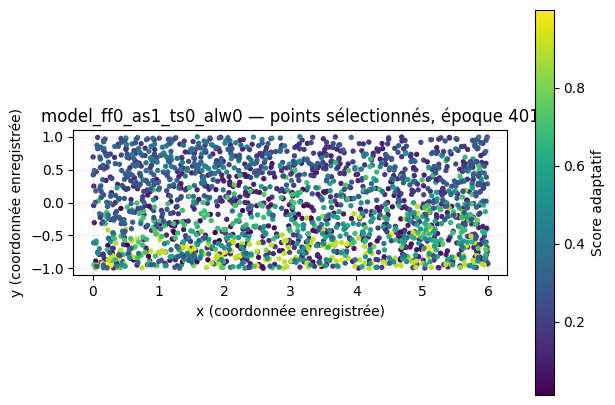

Arrays: {'epochs': (5,), 'windows': (5,), 't_left': (5,), 't_right': (5,), 'points': (5, 2048, 3), 'scores': (5, 2048), 'continuity': (5, 2048), 'vof': (5, 2048), 'momentum': (5, 2048), 'alpha': (5, 2048)}


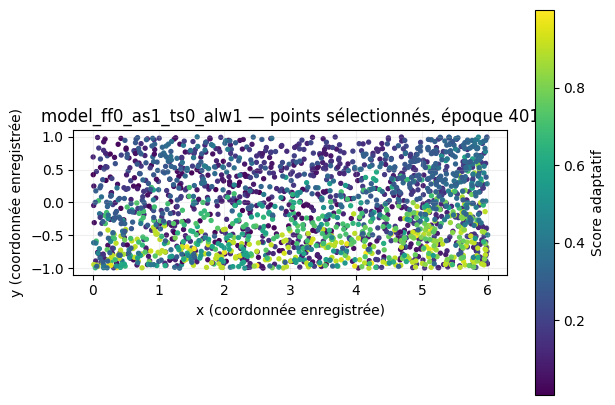

Arrays: {'epochs': (10,), 'windows': (10,), 't_left': (10,), 't_right': (10,), 'points': (10, 2048, 3), 'scores': (10, 2048), 'continuity': (10, 2048), 'vof': (10, 2048), 'momentum': (10, 2048), 'alpha': (10, 2048)}


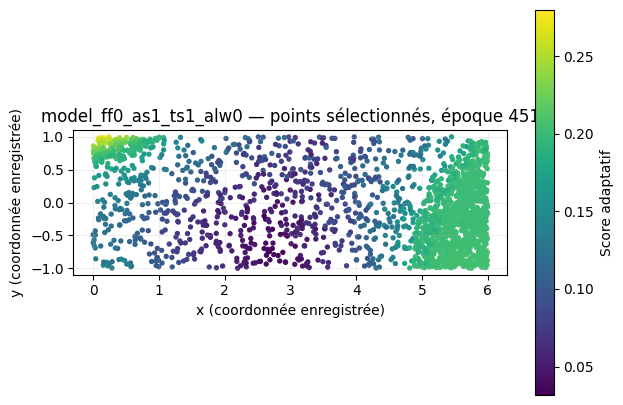

Arrays: {'epochs': (10,), 'windows': (10,), 't_left': (10,), 't_right': (10,), 'points': (10, 2048, 3), 'scores': (10, 2048), 'continuity': (10, 2048), 'vof': (10, 2048), 'momentum': (10, 2048), 'alpha': (10, 2048)}


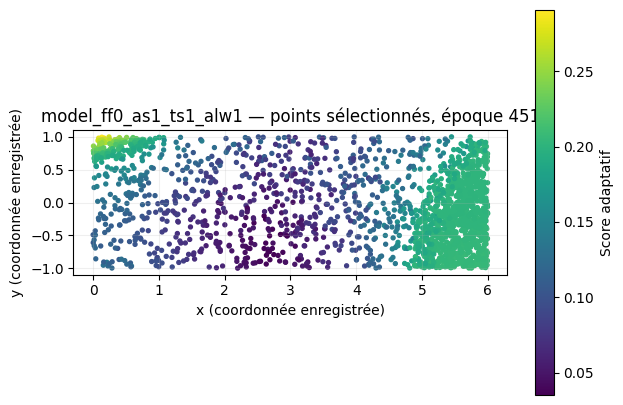

Arrays: {'epochs': (5,), 'windows': (5,), 't_left': (5,), 't_right': (5,), 'points': (5, 2048, 3), 'scores': (5, 2048), 'continuity': (5, 2048), 'vof': (5, 2048), 'momentum': (5, 2048), 'alpha': (5, 2048)}


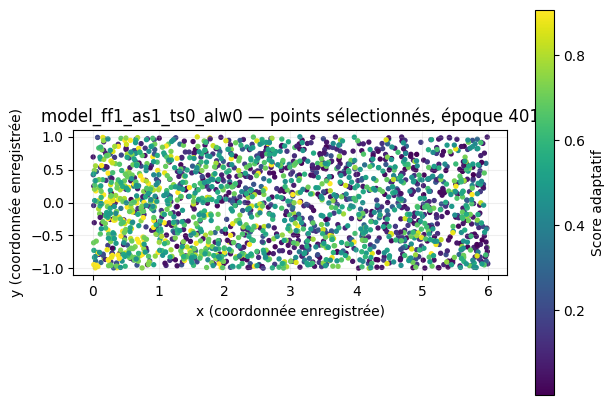

Arrays: {'epochs': (5,), 'windows': (5,), 't_left': (5,), 't_right': (5,), 'points': (5, 2048, 3), 'scores': (5, 2048), 'continuity': (5, 2048), 'vof': (5, 2048), 'momentum': (5, 2048), 'alpha': (5, 2048)}


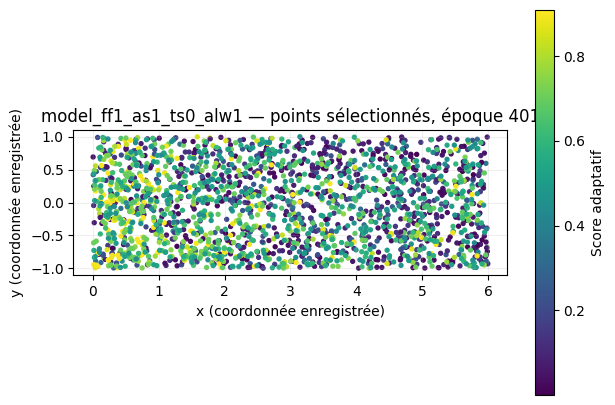

Arrays: {'epochs': (10,), 'windows': (10,), 't_left': (10,), 't_right': (10,), 'points': (10, 2048, 3), 'scores': (10, 2048), 'continuity': (10, 2048), 'vof': (10, 2048), 'momentum': (10, 2048), 'alpha': (10, 2048)}


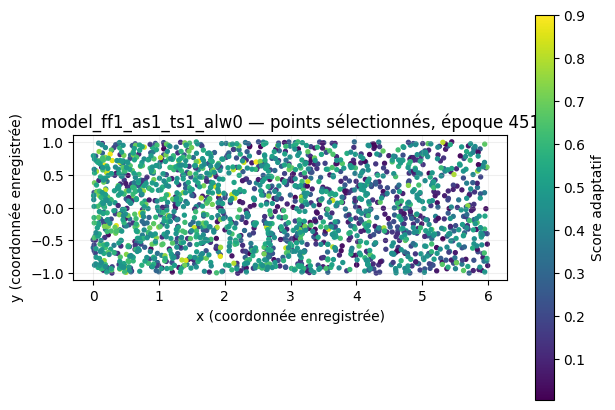

Arrays: {'epochs': (10,), 'windows': (10,), 't_left': (10,), 't_right': (10,), 'points': (10, 2048, 3), 'scores': (10, 2048), 'continuity': (10, 2048), 'vof': (10, 2048), 'momentum': (10, 2048), 'alpha': (10, 2048)}


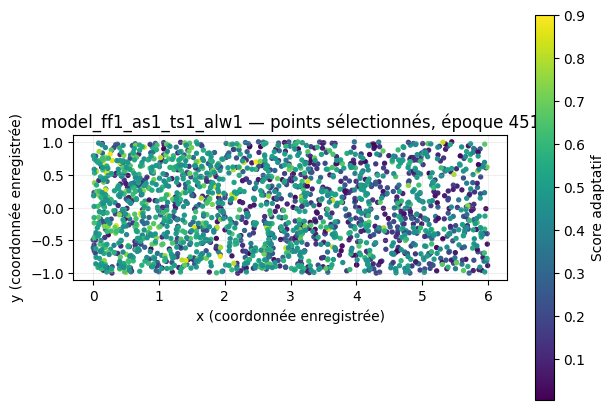

In [19]:
def inspect_adaptive_points(exp_id, update_index=-1):
    path = RUNS_DIR / exp_id / "adaptive_history.npz"
    if not path.exists():
        print(f"Pas d'historique adaptive sampling pour {exp_id}")
        return
    with np.load(path) as d:
        print("Arrays:", {k: d[k].shape for k in d.files})
        pts = d["points"][update_index]
        scores = d["scores"][update_index]
        epoch = d["epochs"][update_index]
        fig, ax = plt.subplots(figsize=(7, 5))
        sc = ax.scatter(pts[:, 0], pts[:, 1], c=scores, s=8)
        fig.colorbar(sc, ax=ax, label="Score adaptatif")
        ax.set(xlabel="x (coordonnée enregistrée)", ylabel="y (coordonnée enregistrée)",
               title=f"{exp_id} — points sélectionnés, époque {epoch}")
        ax.set_aspect("equal", adjustable="box")
        ax.grid(alpha=.2)
        plt.show()

adaptive_ids = [e["id"] for e in experiments if e["sampling"] and (RUNS_DIR/e["id"]/"adaptive_history.npz").exists()]
print("Runs avec points adaptatifs:", adaptive_ids)
for exp_id in adaptive_ids:
    inspect_adaptive_points(exp_id)

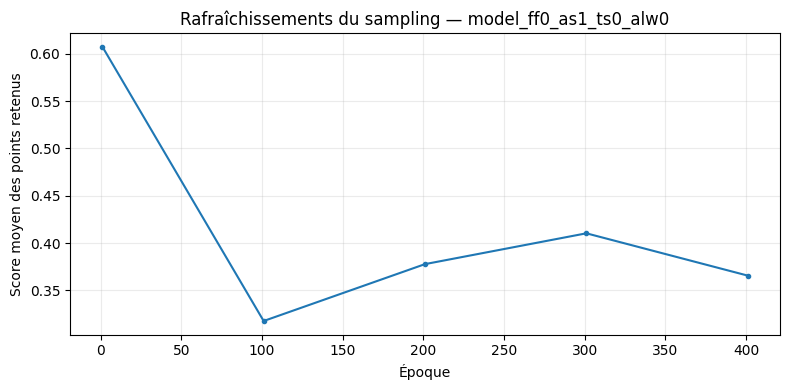

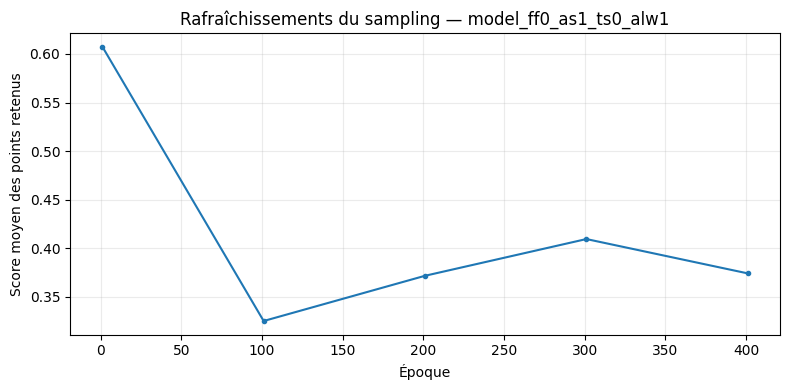

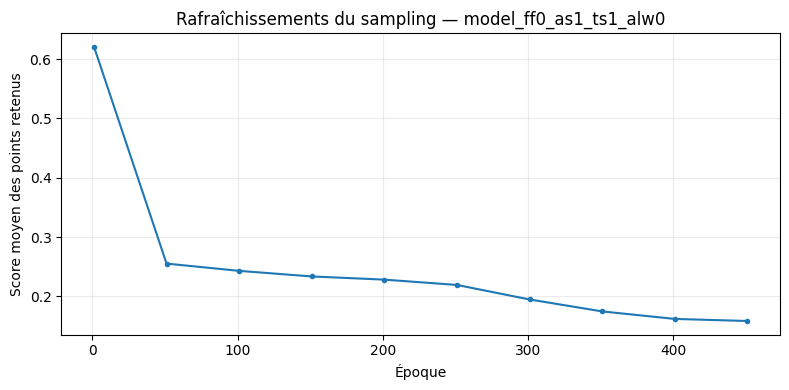

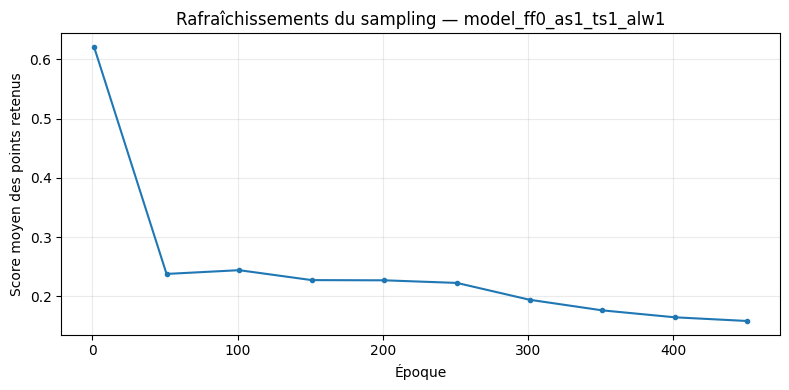

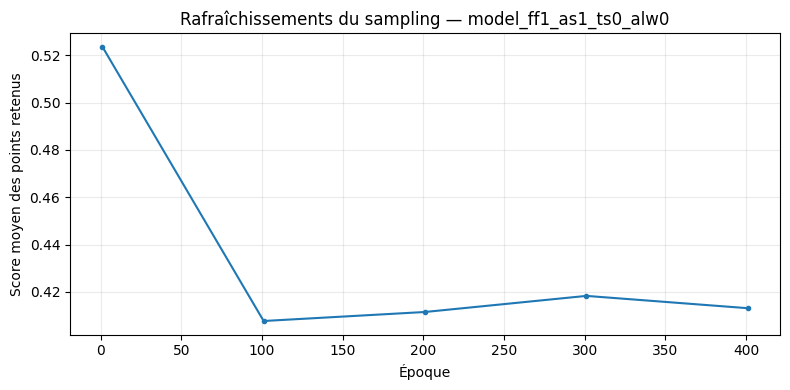

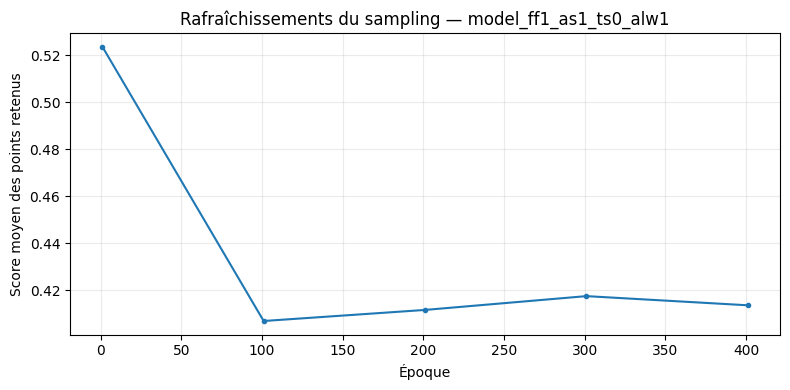

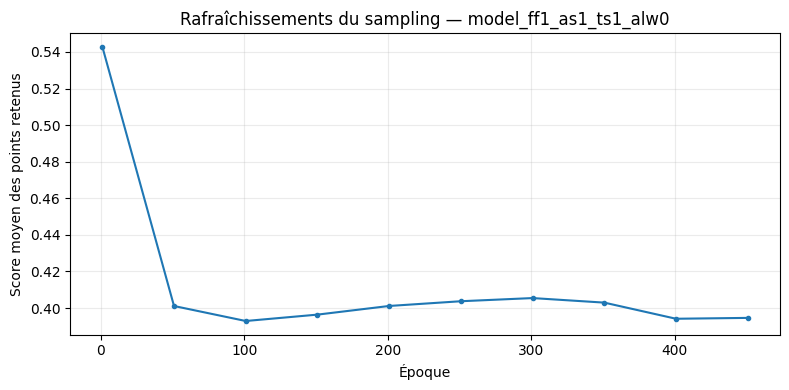

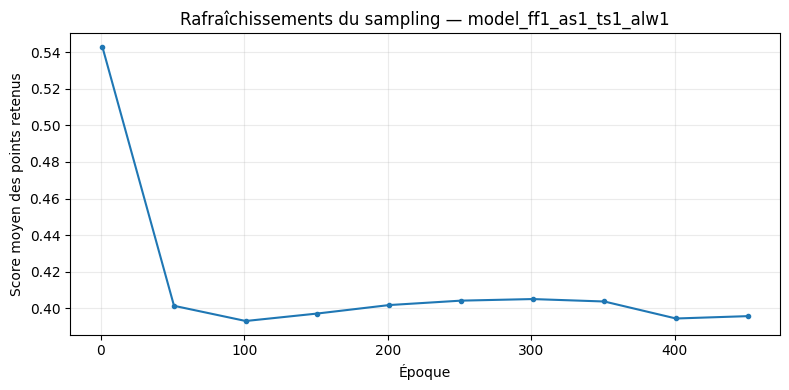

In [18]:
def plot_sampling_score_history(exp_id):
    path = RUNS_DIR / exp_id / "adaptive_history.npz"
    if not path.exists():
        print("Historique absent"); return
    with np.load(path) as d:
        epochs = d["epochs"]
        mean_score = d["scores"].mean(axis=1)
        fig, ax = plt.subplots(figsize=(8, 4))
        ax.plot(epochs, mean_score, marker=".")
        ax.set(xlabel="Époque", ylabel="Score moyen des points retenus",
               title=f"Rafraîchissements du sampling — {exp_id}")
        ax.grid(alpha=.25)
        plt.tight_layout()

for exp_id in adaptive_ids:
    plot_sampling_score_history(exp_id)

## Adaptive weighting — historique GradNorm

Le fichier `adaptive_weights.json` contient les poids au fil des époques pour les termes gérés par GradNorm. Les poids étant de nature adaptative, leur trajectoire (stabilité, saturation aux bornes, changements brusques) est à analyser conjointement avec les pertes.

Runs GradNorm: ['model_ff0_as0_ts0_alw1', 'model_ff0_as0_ts1_alw1', 'model_ff0_as1_ts0_alw1', 'model_ff0_as1_ts1_alw1', 'model_ff1_as0_ts0_alw1', 'model_ff1_as0_ts1_alw1', 'model_ff1_as1_ts0_alw1', 'model_ff1_as1_ts1_alw1']


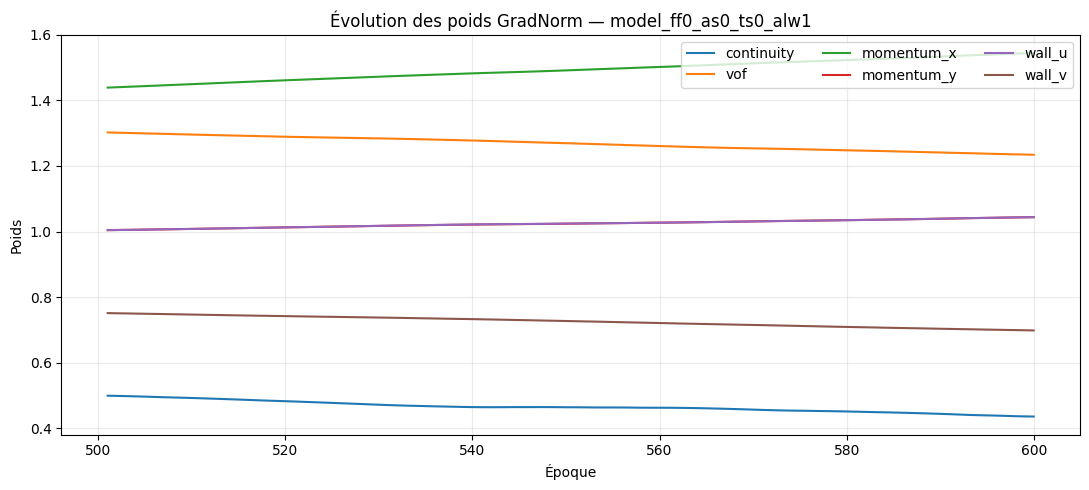

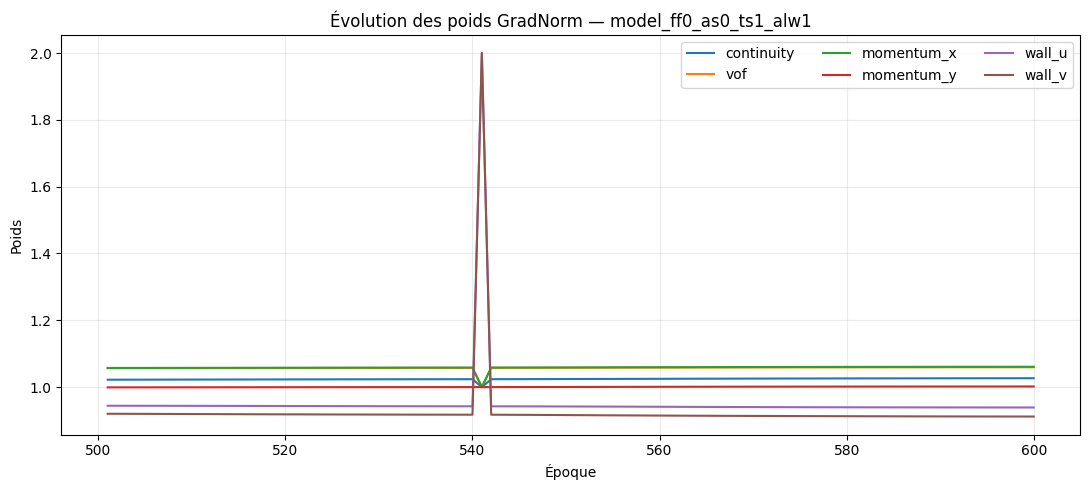

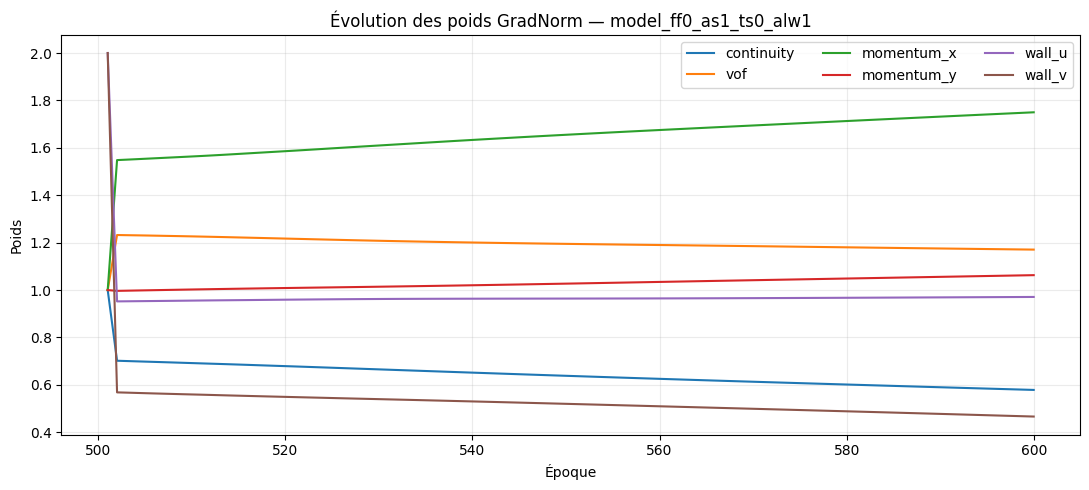

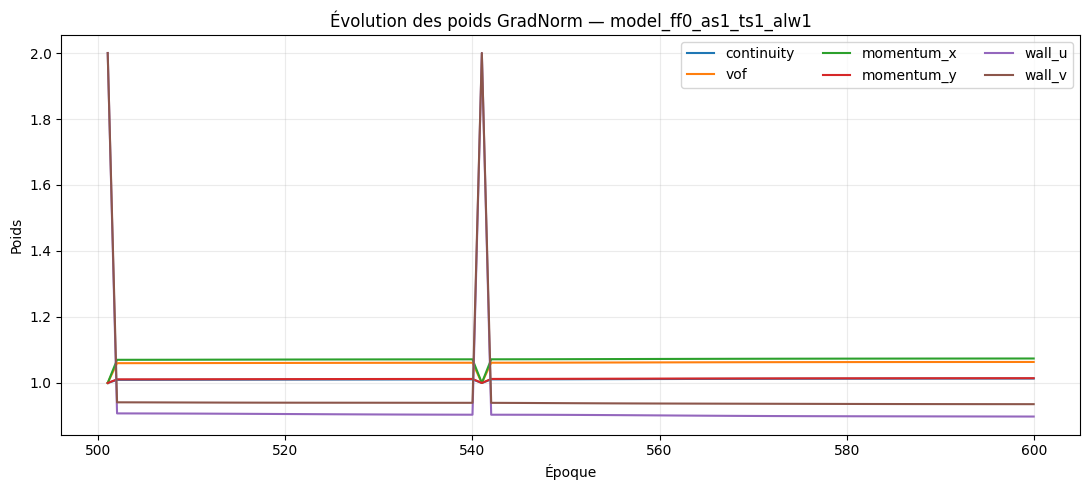

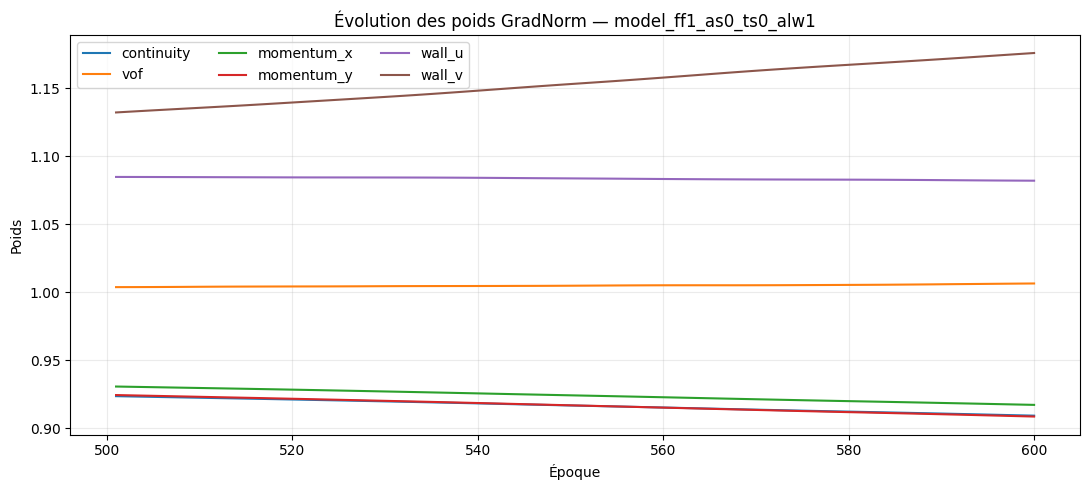

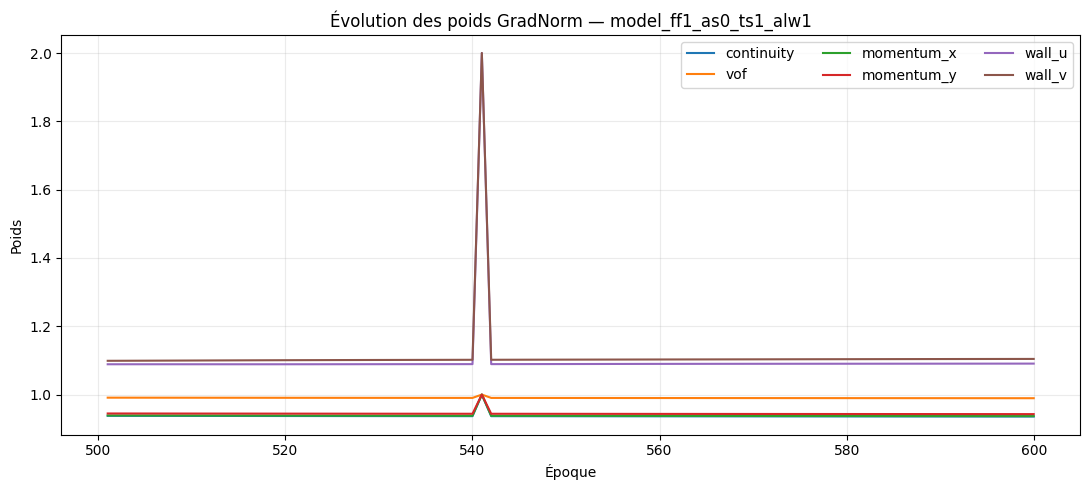

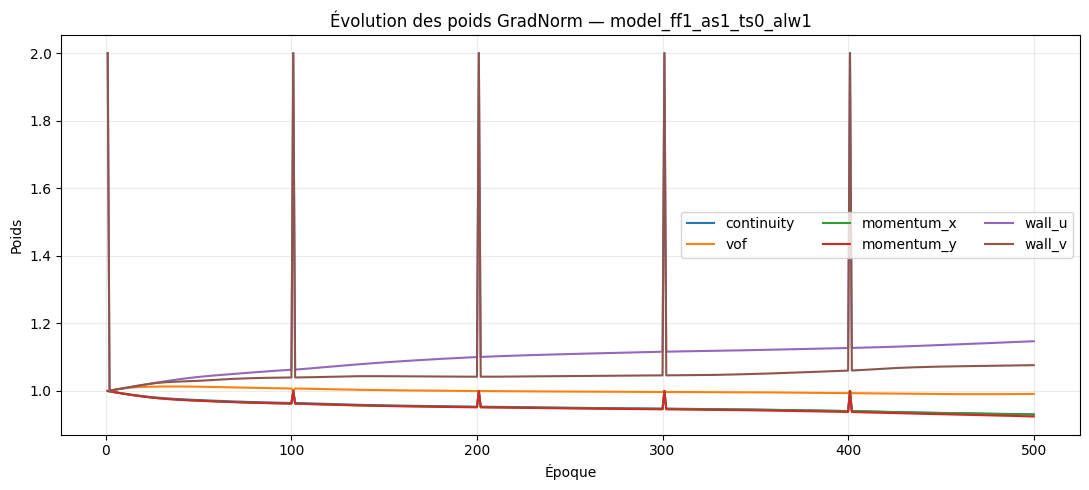

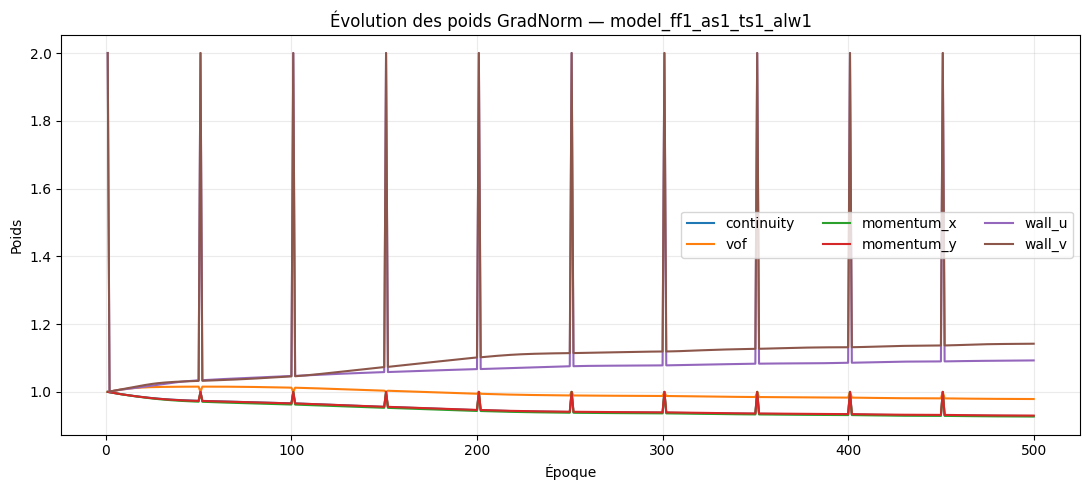

In [20]:
def plot_gradnorm_weights(exp_id):
    path = RUNS_DIR / exp_id / "adaptive_weights.json"
    if not path.exists():
        print(f"Pas d'historique GradNorm pour {exp_id}")
        return
    df = pd.DataFrame(json.loads(path.read_text(encoding="utf-8")))
    cols = [c for c in df.columns if c not in ("epoch", "window")]
    fig, ax = plt.subplots(figsize=(11, 5))
    for c in cols:
        ax.plot(df["epoch"], df[c], label=c)
    ax.set(xlabel="Époque", ylabel="Poids", title=f"Évolution des poids GradNorm — {exp_id}")
    ax.grid(alpha=.25)
    ax.legend(ncol=3)
    plt.tight_layout()
    return df

gradnorm_ids = [e["id"] for e in experiments if e["gradnorm"] and (RUNS_DIR/e["id"]/"adaptive_weights.json").exists()]
print("Runs GradNorm:", gradnorm_ids)
for exp_id in gradnorm_ids:
    weights_df = plot_gradnorm_weights(exp_id)

##  Tableau de synthèse et export

Ce tableau rassemble les quatre facteurs, les indicateurs et le coût temps. Export CSV pour analyses complémentaires.

In [ ]:
if len(metrics):
    summary = metrics.copy()
    if "seconds" in results_df:
        summary = summary.merge(results_df[["id", "seconds", "n_epochs"]], on="id", how="left")
    display(summary.sort_values("final"))
    summary.to_csv(RUNS_DIR / "full_ablation_summary.csv", index=False)
print("Artefacts dans:", RUNS_DIR.resolve())

## Conclusions — grille de lecture

- **Convergence** : comparer pente terminale, plateau et temps/époque ; vérifier que la diminution du total ne masque pas une perte physique stagnante.
- **Fourier Features** : observer notamment la vitesse de réduction initiale et les éventuelles oscillations.
- **Segmentation temporelle** : mettre en regard la convergence locale et les transitions de fenêtre (`window`, `t_left`, `t_right`).
- **Adaptive sampling** : vérifier si les points sont concentrés sur des zones de forte difficulté et si les scores moyens changent au fil de l'entraînement.
- **GradNorm** : vérifier la stabilité des poids et leur relation aux pertes associées.
- **Robustesse** : effectuer plusieurs seeds (et comparer moyennes/écarts-types) avant de conclure à un gain. Une seule expérience par combinaison ne mesure pas l'incertitude.

**Attention à l'équité de comparaison :** les mêmes epochs ne signifient pas forcément le même temps de calcul, en particulier avec scoring adaptatif et GradNorm. Rapporter les deux.